In [1]:
import spikeinterface.full as si
import spikeinterface.widgets as sw
import spikeinterface.extractors as se
import spikeinterface.sorters as ss
import spikeinterface.qualitymetrics as sqm
import probeinterface as pi
from probeinterface import generate_tetrode, ProbeGroup, generate_multi_shank, generate_linear_probe
from probeinterface.plotting import plot_probe, plot_probegroup
#import mountainsort5 as ms5
#from mountainsort5.util import create_cached_recording
import kilosort
from mpl_toolkits.mplot3d import Axes3D
import matplotlib.cm as cm
import math


import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import pandas as pd
from pathlib import Path
import os

import pynapple as nap

import warnings
warnings.simplefilter("ignore")

#%matplotlib widget
print(f"SpikeInterface version: {si.__version__}")
np.set_printoptions(threshold=np.inf)

global_job_kwargs = dict(n_jobs=-1, chunk_duration="1s",progress_bar=True)
si.set_global_job_kwargs(**global_job_kwargs)


SpikeInterface version: 0.101.1


In [2]:
spike_times = np.load("C:\\Users\\ryanz\\Documents\\nac_analysis\\sorter_output\\CPWI18_2019-07-29_13-50-50_LRRLLR 400uA_output\\sorter_output\\spike_times.npy")
spike_clusters = np.load("C:\\Users\\ryanz\\Documents\\nac_analysis\\sorter_output\\CPWI18_2019-07-29_13-50-50_LRRLLR 400uA_output\\sorter_output\\spike_clusters.npy")

In [3]:
#event types with states
path_to_channel_states = "C:\\Users\\ryanz\\Documents\\nac_analysis\\raw\\CPWI18_2019-07-29_13-50-50_LRRLLR 400uA\\CPWI18_2019-07-29_13-50-50_LRRLLR 400uA\\experiment1\\recording1\\events\\Rhythm_FPGA-100.0\\TTL_1\\channel_states.npy"
channel_states = np.load(path_to_channel_states)


path_to_channel_timestamps = "C:\\Users\\ryanz\\Documents\\nac_analysis\\raw\\CPWI18_2019-07-29_13-50-50_LRRLLR 400uA\\CPWI18_2019-07-29_13-50-50_LRRLLR 400uA\\experiment1\\recording1\\events\\Rhythm_FPGA-100.0\\TTL_1\\timestamps.npy"
timestamps = np.load(path_to_channel_timestamps)

timestamps = timestamps / 30000


In [4]:
vals = np.unique(np.abs(channel_states))

events = {}
for i, channel in enumerate(channel_states):
    if channel in events:
        events[channel].append(timestamps[i])
        continue
    
    events[channel] = [timestamps[i]]

events.keys()

dict_keys([2, -2, 6, -6, 4, -4, 5, -5, 1, -1])

In [5]:
events[6]

[686.8454666666667,
 704.8251333333334,
 705.8251,
 727.9946666666667,
 730.9246333333333,
 731.1746,
 731.5746,
 740.7044333333333,
 767.1339,
 768.3238666666666,
 787.7935,
 791.3334666666667,
 791.5834333333333,
 792.0334333333333,
 801.1432333333333,
 801.2232333333334,
 811.2230666666667,
 836.7725333333333,
 837.7725333333333,
 855.1721666666666,
 857.7721333333334,
 858.4221333333334,
 861.7720666666667,
 866.2219666666666,
 871.8318666666667,
 872.1318666666666,
 872.4818666666666,
 875.4818,
 884.2316,
 895.2214,
 896.2213666666667,
 906.2212,
 907.8211666666666,
 921.0309,
 922.0308666666666,
 932.0307,
 933.0306666666667,
 943.0304666666667,
 944.0304333333333,
 955.5402,
 956.5402,
 958.6901666666666,
 968.6899666666667,
 978.6897666666666,
 979.6897333333334,
 990.5295333333333,
 991.5295,
 994.2894666666666,
 1004.2892666666667,
 1019.4189666666666,
 1020.4189333333334,
 1042.9185,
 1043.9184666666667,
 1058.7182,
 1065.2580666666668,
 1065.8080666666667,
 1069.158,
 1079

In [6]:
events[-6]

[686.8562,
 704.9058333333334,
 705.8358333333333,
 728.0354,
 731.0053333333333,
 731.4253333333334,
 733.5753,
 740.7151333333334,
 767.2146,
 768.3346,
 787.8342,
 791.4141666666667,
 791.8341333333333,
 794.0341,
 801.1539666666666,
 801.2739666666666,
 811.2337666666666,
 836.7932666666667,
 837.7832333333333,
 855.2029,
 857.8528333333334,
 860.4228,
 861.7827666666667,
 866.2626666666666,
 871.9125666666666,
 872.3825666666667,
 874.4825333333333,
 875.4925,
 884.2623333333333,
 895.2921,
 896.2321,
 906.2419,
 907.8318666666667,
 921.1116,
 922.0416,
 932.1114,
 933.0413666666667,
 943.1111666666667,
 944.0411666666666,
 955.6209333333334,
 956.5509,
 958.7408666666666,
 968.7006666666666,
 978.7704666666667,
 979.7004666666667,
 990.6102333333333,
 991.5402333333334,
 994.3401666666666,
 1004.2999666666667,
 1019.4996666666667,
 1020.4296666666667,
 1042.9992333333332,
 1043.9292,
 1058.7489333333333,
 1065.3387666666667,
 1067.8087333333333,
 1069.1687,
 1079.1785,
 1080.1685

In [7]:
code_mapping = {
    2: "right_nosepoke_entry",
    4: "tones",
    5: "left_nosepoke_entry",
    6: "task_event",
    18: "trial_start",
    19: "shock_no_seek",
    20: "no_shock_no_seek",
    21: "no_shock_seek_completion_valid",
    22: "shock_seek_completion_valid",
    23: "no_shock_seek_completion_invalid",
    24: "shock_seek_completion_invalid",
    25: "no_take_limit_passed",
    26: "correct_take"
}

events[18] = []
events[19] = []
events[20] = []
events[21] = []
events[22] = []
events[23] = []
events[24] = []
events[25] = []
events[26] = []

In [8]:
events[6]

[686.8454666666667,
 704.8251333333334,
 705.8251,
 727.9946666666667,
 730.9246333333333,
 731.1746,
 731.5746,
 740.7044333333333,
 767.1339,
 768.3238666666666,
 787.7935,
 791.3334666666667,
 791.5834333333333,
 792.0334333333333,
 801.1432333333333,
 801.2232333333334,
 811.2230666666667,
 836.7725333333333,
 837.7725333333333,
 855.1721666666666,
 857.7721333333334,
 858.4221333333334,
 861.7720666666667,
 866.2219666666666,
 871.8318666666667,
 872.1318666666666,
 872.4818666666666,
 875.4818,
 884.2316,
 895.2214,
 896.2213666666667,
 906.2212,
 907.8211666666666,
 921.0309,
 922.0308666666666,
 932.0307,
 933.0306666666667,
 943.0304666666667,
 944.0304333333333,
 955.5402,
 956.5402,
 958.6901666666666,
 968.6899666666667,
 978.6897666666666,
 979.6897333333334,
 990.5295333333333,
 991.5295,
 994.2894666666666,
 1004.2892666666667,
 1019.4189666666666,
 1020.4189333333334,
 1042.9185,
 1043.9184666666667,
 1058.7182,
 1065.2580666666668,
 1065.8080666666667,
 1069.158,
 1079

In [9]:
differentials = []
for i in range(len(events[6])):
    differential = events[-6][i] - events[6][i]
    differential = math.trunc(differential * 100) / 100
    differentials.append(differential)
    
differentials


[0.01,
 0.08,
 0.01,
 0.04,
 0.08,
 0.25,
 2.0,
 0.01,
 0.08,
 0.01,
 0.04,
 0.08,
 0.25,
 2.0,
 0.01,
 0.05,
 0.01,
 0.02,
 0.01,
 0.03,
 0.08,
 2.0,
 0.01,
 0.04,
 0.08,
 0.25,
 2.0,
 0.01,
 0.03,
 0.07,
 0.01,
 0.02,
 0.01,
 0.08,
 0.01,
 0.08,
 0.01,
 0.08,
 0.01,
 0.08,
 0.01,
 0.05,
 0.01,
 0.08,
 0.01,
 0.08,
 0.01,
 0.05,
 0.01,
 0.08,
 0.01,
 0.08,
 0.01,
 0.03,
 0.08,
 2.0,
 0.01,
 0.02,
 0.01,
 0.08,
 0.01,
 0.08,
 0.01,
 0.08,
 0.01,
 0.08,
 0.01,
 0.08,
 0.01,
 0.08,
 0.01,
 0.08,
 0.01,
 0.08,
 0.01,
 0.08,
 0.01,
 0.08,
 0.01,
 0.08,
 0.01,
 0.08,
 0.01,
 0.08,
 0.01,
 0.08,
 0.01,
 0.08,
 0.01,
 0.08,
 0.01,
 0.08,
 0.01,
 0.08,
 0.01,
 0.08,
 0.01,
 0.08,
 0.01,
 0.08,
 0.01,
 0.08,
 0.01,
 0.08,
 0.01,
 0.08,
 0.01,
 0.08,
 0.01,
 0.08,
 0.01,
 0.08,
 0.01,
 0.08,
 0.01,
 0.08,
 0.01,
 0.08,
 0.01,
 0.05,
 0.01,
 0.08,
 0.01,
 0.08,
 0.01,
 0.03,
 0.08,
 2.0,
 0.01,
 0.02,
 0.01,
 0.08,
 0.01,
 0.08,
 0.01,
 0.08,
 0.01,
 0.08,
 0.01,
 0.08,
 0.01,
 0.08,
 0.01,
 0.08

In [10]:
for i in range(len(events[6])):
    differential = differentials[i]
    
    if differential == 0.01:
        events[18].append(events[6][i])
        
    elif differential == 0.02:
        events[19].append(events[6][i])
        
    elif differential == 0.08:
        if differentials[i + 1] == 0.25 or differentials[i + 1] == 2.0:
            events[26].append(events[6][i])
        else:
            events[20].append(events[6][i])
        
    elif differential == 0.03:
        events[21].append(events[6][i])
        
    elif differential == 0.04:
        events[22].append(events[6][i])
        
    elif differential == 0.05:
        events[23].append(events[6][i])
        
    elif differential == 0.06:
        events[24].append(events[6][i])
        
    elif differential == 0.07:
        events[25].append(events[6][i])
    
    
    


In [11]:
events

{2: [685.8355,
  694.5553333333334,
  694.8053333333334,
  709.0850333333333,
  713.4649666666667,
  725.5147333333333,
  727.5747,
  727.9946666666667,
  743.1044,
  747.7243,
  767.3139,
  770.8838333333333,
  776.8537333333334,
  779.2736666666667,
  786.7135333333333,
  787.7935,
  788.2634666666667,
  788.3435,
  814.793,
  816.8629333333333,
  819.1029,
  819.2029,
  838.7625,
  844.4024,
  844.4724,
  852.8822333333334,
  855.1721666666666,
  855.8621666666667,
  864.752,
  864.912,
  865.822,
  865.9419666666666,
  866.2219666666666,
  881.2317,
  882.0616666666666,
  884.0216333333333,
  884.1116,
  884.2316,
  885.0016,
  906.6011666666667,
  906.7511666666667,
  911.0011,
  945.5104333333334,
  980.4797333333333,
  1009.3991666666667,
  1029.5687666666668,
  1032.8687,
  1045.5984666666666,
  1049.0384,
  1050.3683666666666,
  1051.0283666666667,
  1058.7182,
  1101.1873666666668,
  1104.2273,
  1142.3365666666666,
  1169.7160333333334,
  1171.136,
  1268.8640666666668,
  12

In [12]:
spike_times.shape

(3757567,)

In [13]:
spike_times[:20]

array([ 151,  397,  636,  659,  730,  756,  791,  892,  935, 1272, 1322,
       1329, 1475, 1525, 1540, 1621, 1673, 1980, 2118, 2141], dtype=int64)

In [14]:
spike_clusters.shape

(3757567,)

In [15]:
spike_clusters[:20]

array([15, 57, 51, 63, 28, 12, 10,  9, 51, 60, 38, 28,  5, 28,  8,  9,  0,
       16, 51, 31])

In [16]:
spike_dict = {}

for cluster_id in np.unique(spike_clusters):
    spike_dict[cluster_id] = spike_times[spike_clusters == cluster_id]


sample_rate = 30000  
spike_dict_sec = {k: v / sample_rate for k, v in spike_dict.items()}


event_timestamps = np.array(events[5])



In [17]:
code_mapping = {
    2: "right_nosepoke_entry",
    4: "tones",
    5: "left_nosepoke_entry",
    6: "task_event",
    18: "trial_start",
    19: "shock_no_seek",
    20: "no_shock_no_seek",
    21: "no_shock_seek_completion_valid",
    22: "shock_seek_completion_valid",
    23: "no_shock_seek_completion_invalid",
    24: "shock_seek_completion_invalid",
    25: "no_take_limit_passed",
    26: "correct_take"
}


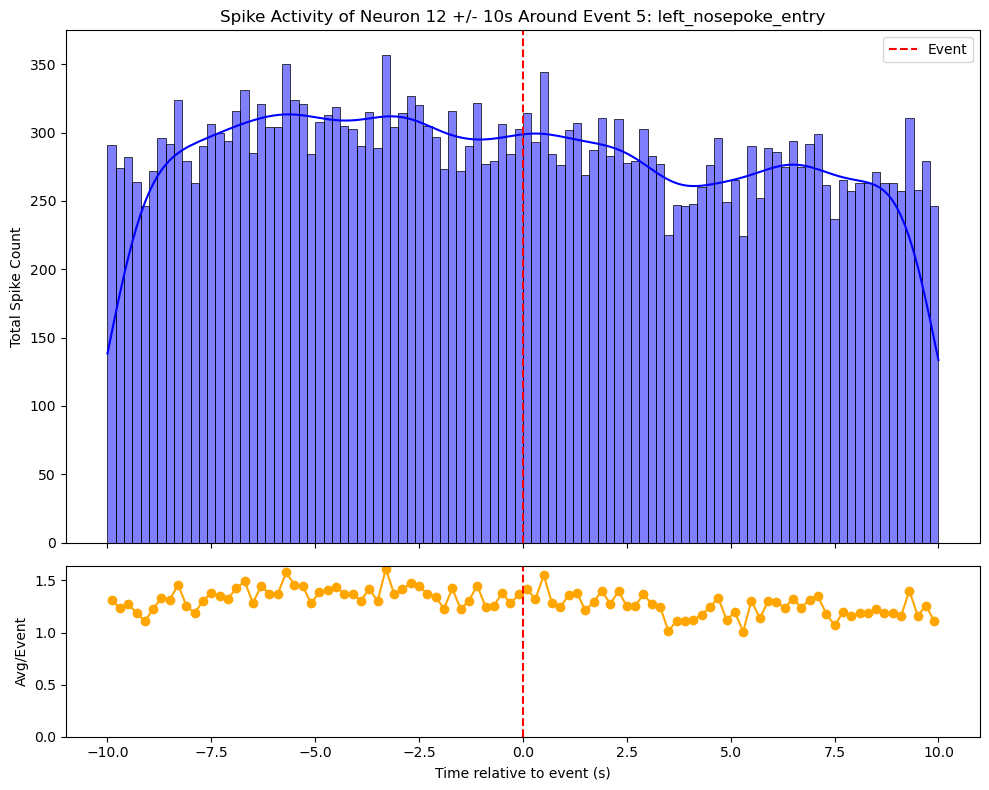

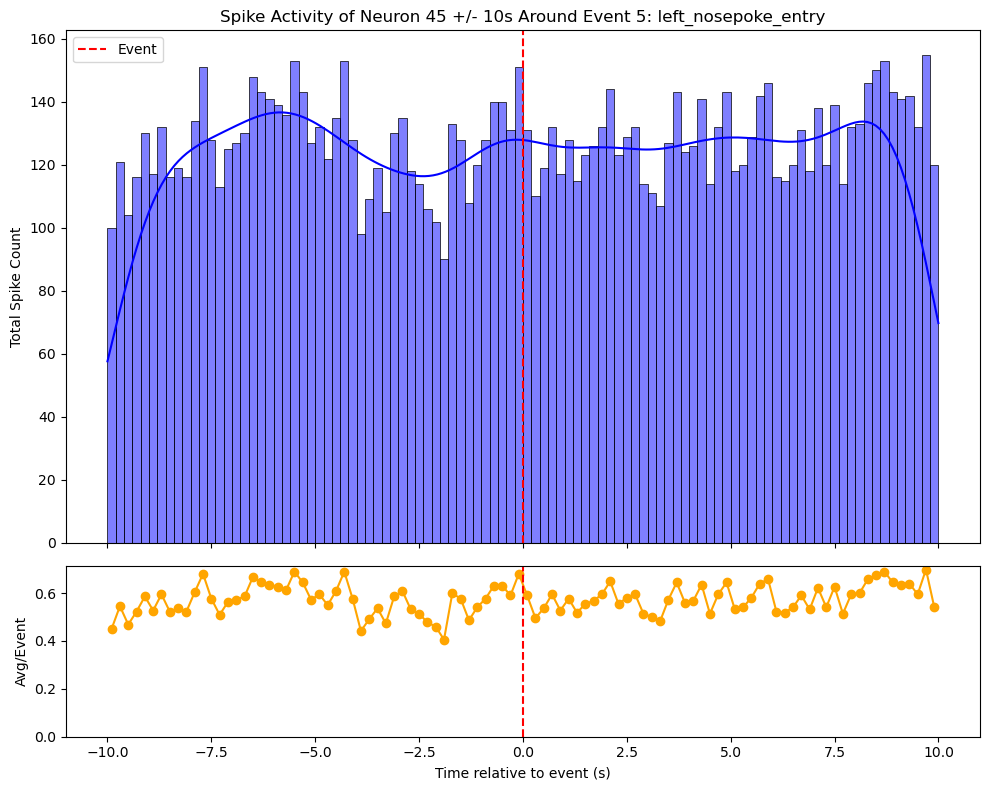

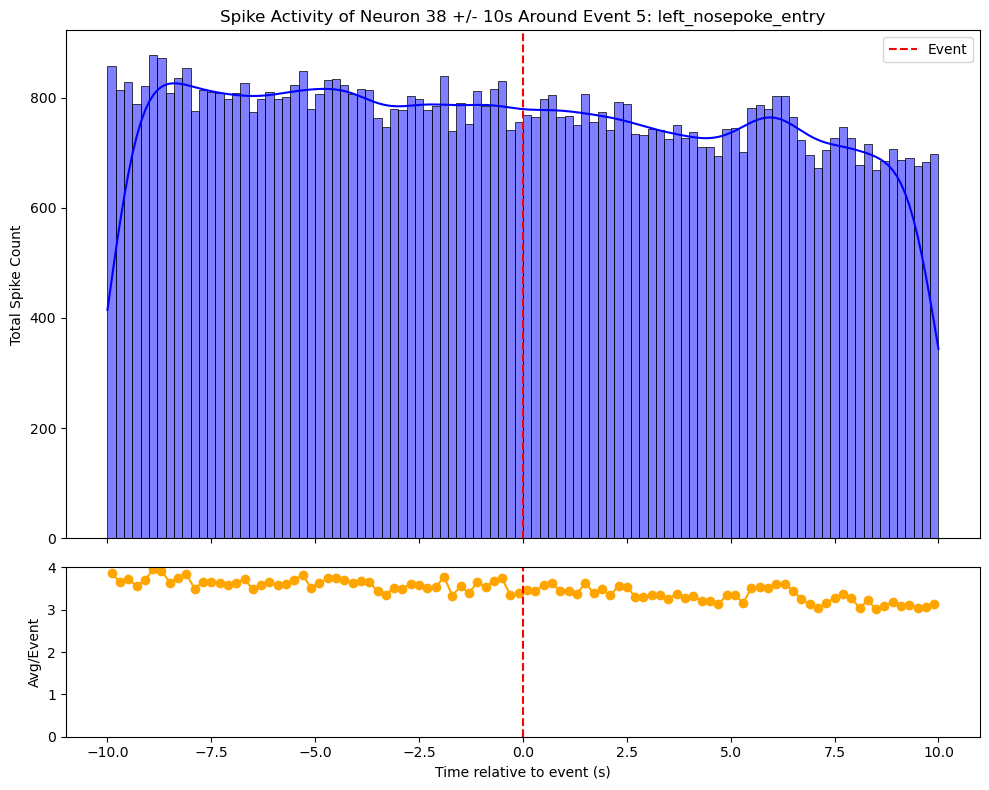

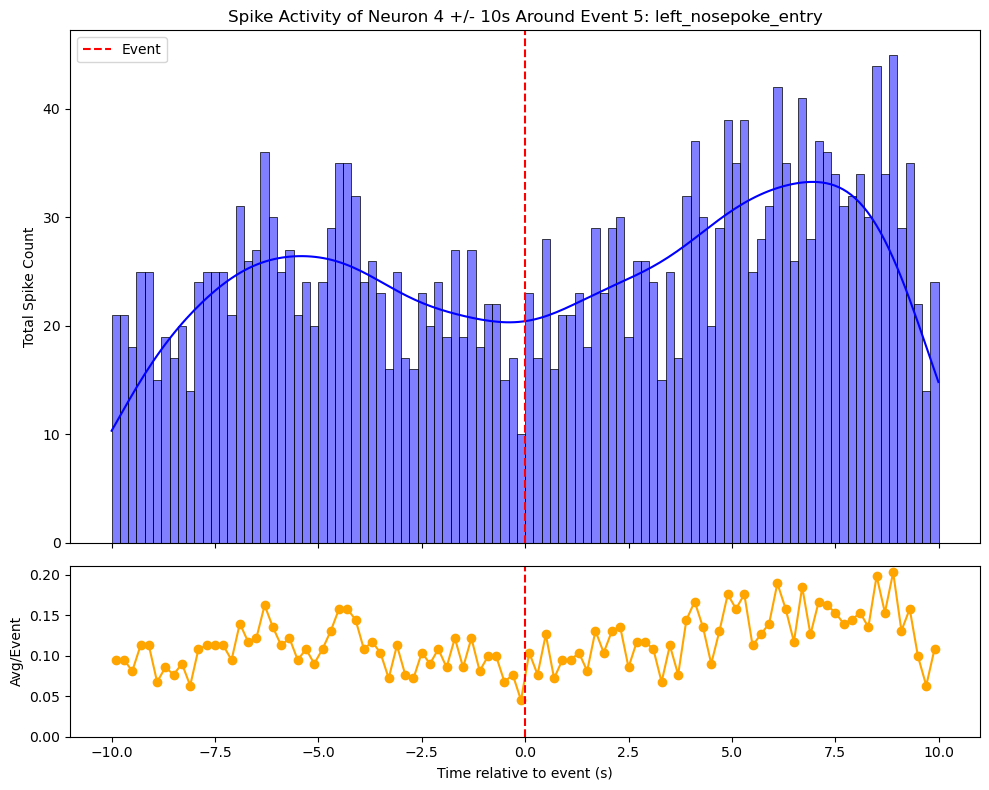

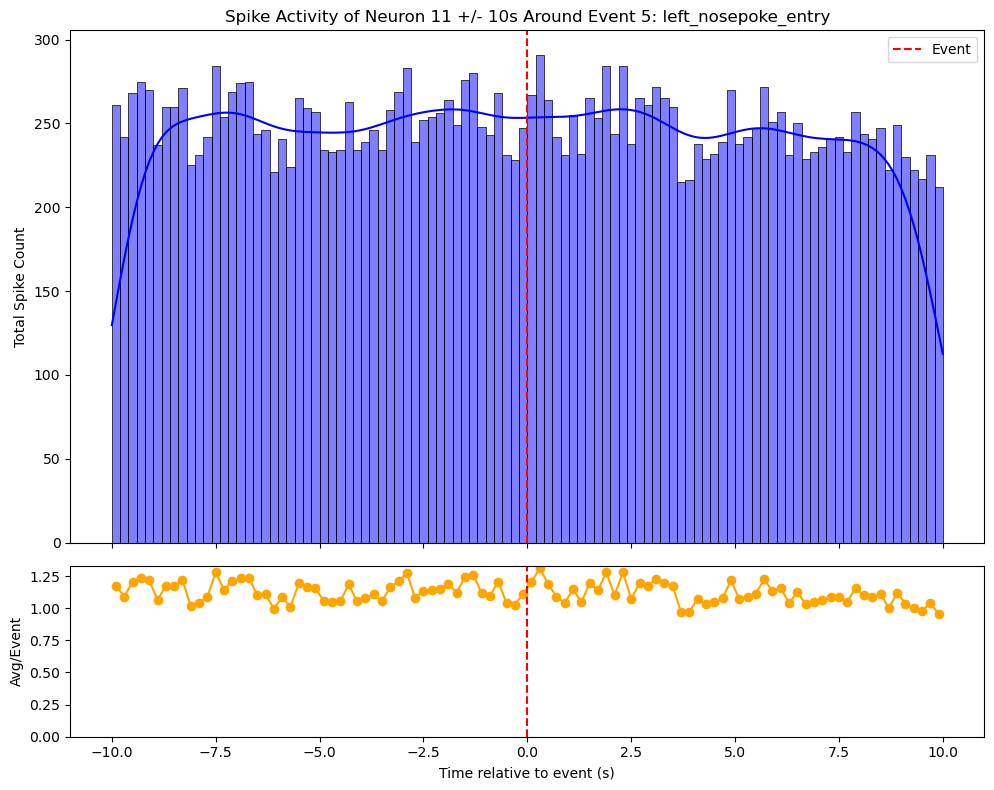

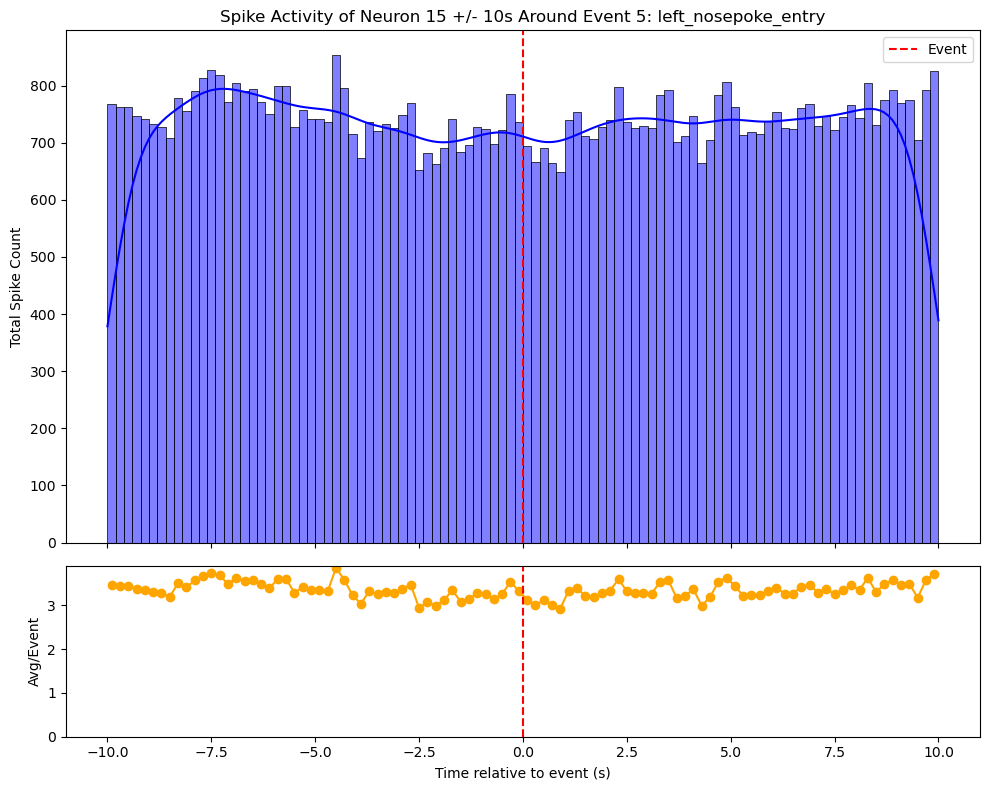

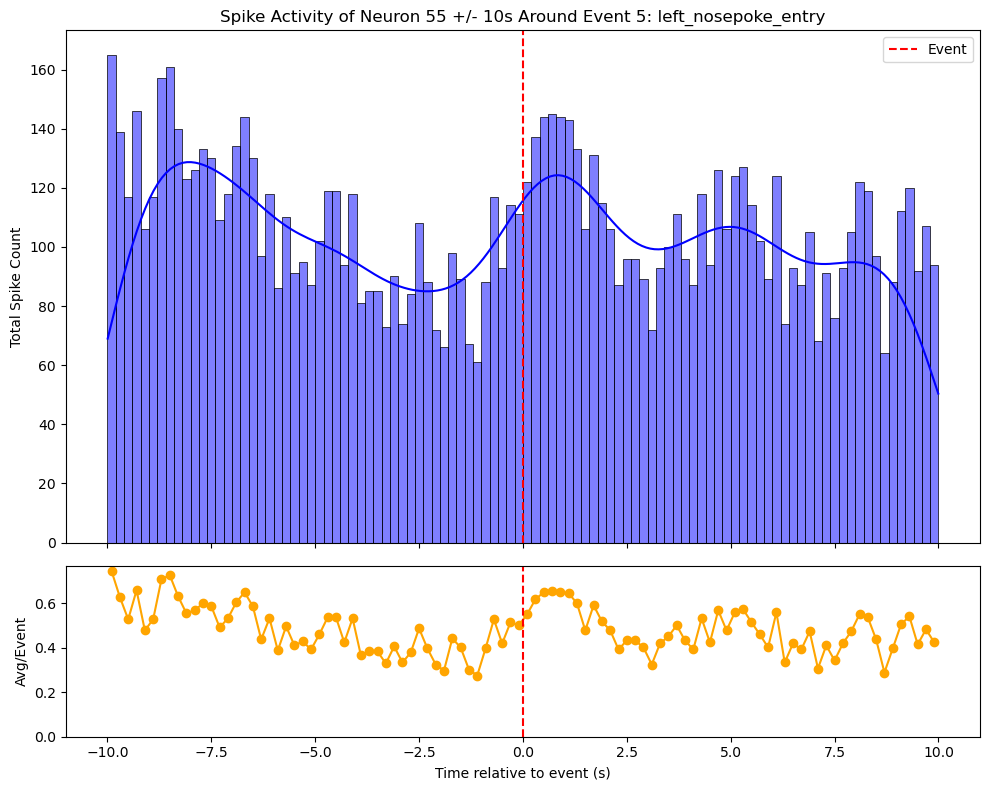

In [18]:
%matplotlib inline
event = 5

for unit in [12,45,38,4,11,15,55]:
        
    event_timestamps = np.array(events[event])
    num_events = len(event_timestamps)

    time_window = 10
    spike_times = spike_dict_sec[unit]

    spikes_around_events = []
    for event_time in event_timestamps:
        spikes_in_window = spike_times[(spike_times >= event_time - time_window) & 
                                       (spike_times <= event_time + time_window)]
        spikes_shifted = spikes_in_window - event_time
        spikes_around_events.extend(spikes_shifted)

    # Bin setup
    bin_edges = np.linspace(-time_window, time_window, 101)  # 25 bins
    bin_centers = (bin_edges[:-1] + bin_edges[1:]) / 2

    # Histogram (summed spike count)
    summed_counts, _ = np.histogram(spikes_around_events, bins=bin_edges)

    # Average per event
    avg_counts = summed_counts / num_events

    # Plot both
    fig, axs = plt.subplots(2, 1, figsize=(10,8), sharex=True, gridspec_kw={'height_ratios': [3, 1]})
    
    # Top: Total spike counts
    sns.histplot(spikes_around_events, bins=bin_edges, kde=True, ax=axs[0], color='blue', stat='count', edgecolor='black')
    axs[0].axvline(0, color='red', linestyle='--', label='Event')
    axs[0].set_ylabel('Total Spike Count')
    axs[0].set_title(f'Spike Activity of Neuron {unit} +/- {time_window}s Around Event {event}: {code_mapping[event]}')
    axs[0].legend()
    


    # Bottom: Average spike counts
    axs[1].plot(bin_centers, avg_counts, color='orange', marker='o')
    axs[1].axvline(0, color='red', linestyle='--')
    axs[1].set_xlabel('Time relative to event (s)')
    axs[1].set_ylabel('Avg/Event')
    axs[1].set_ylim(bottom=0)

    plt.tight_layout()
    plt.show()

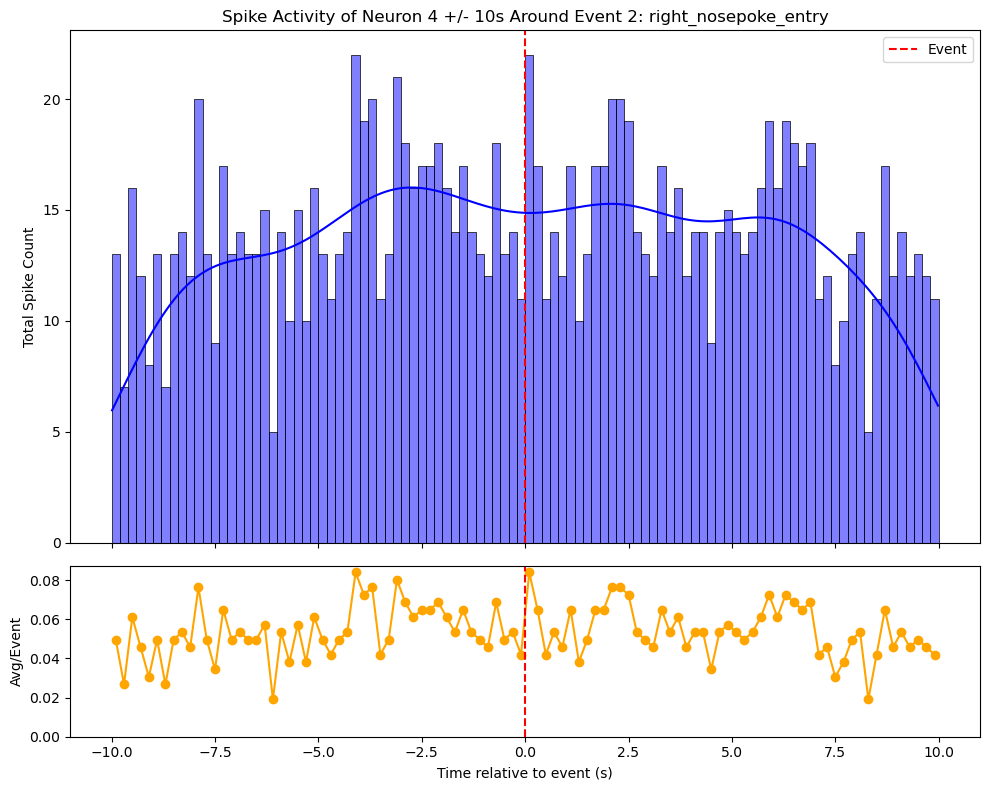

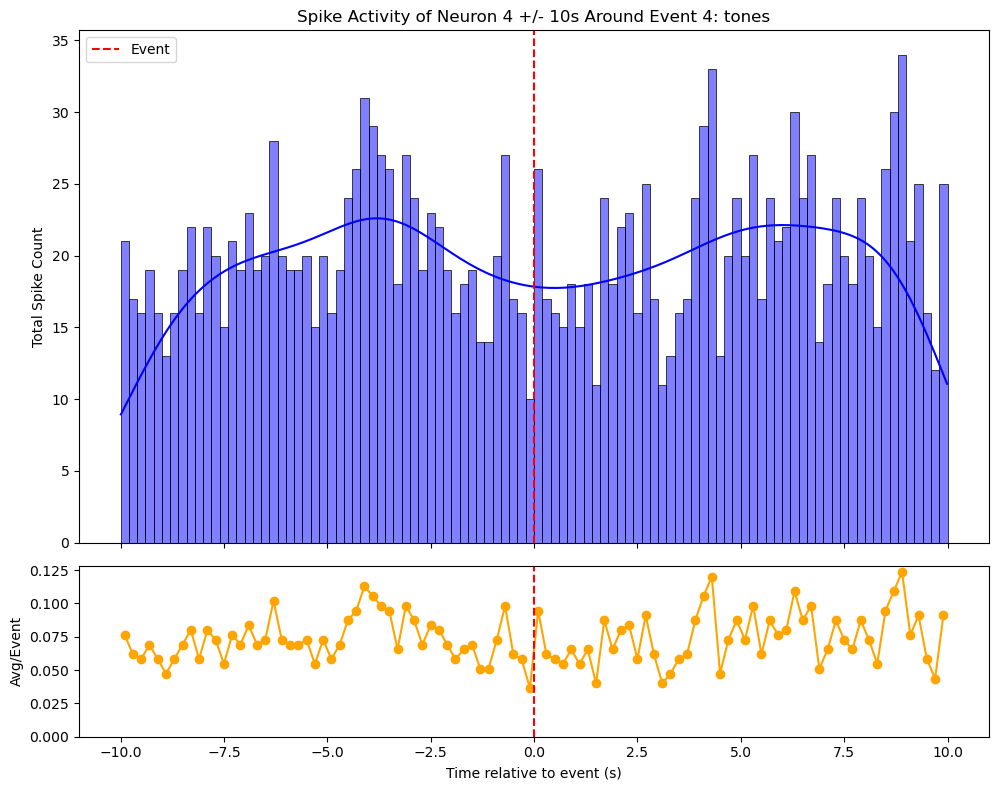

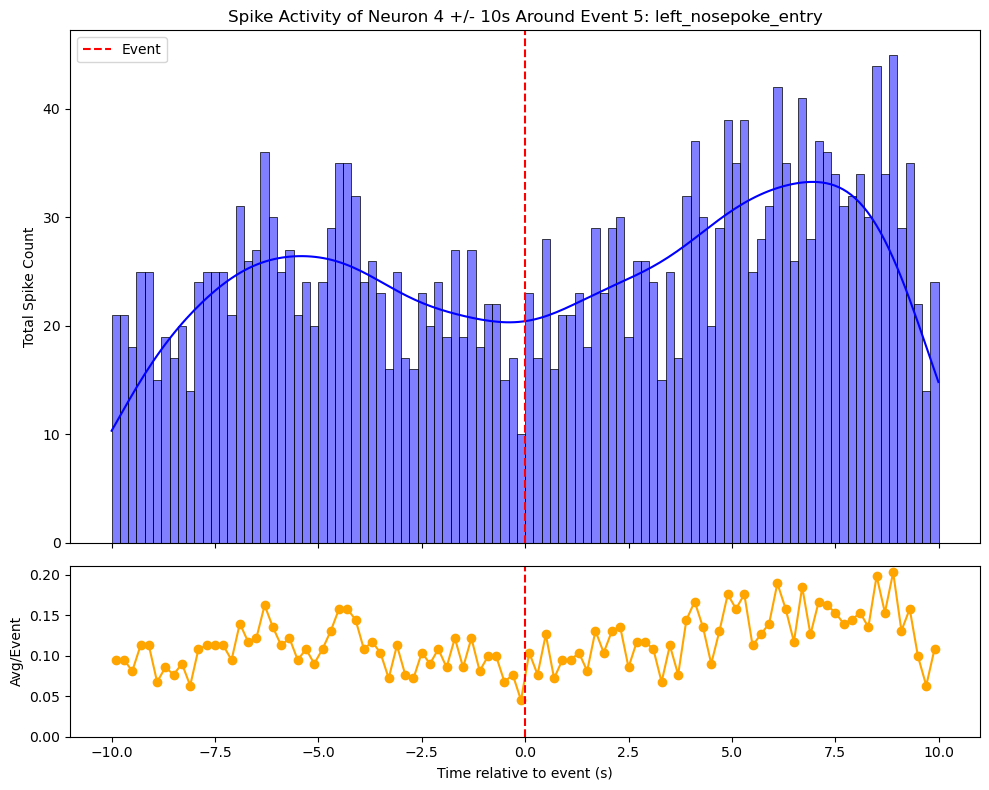

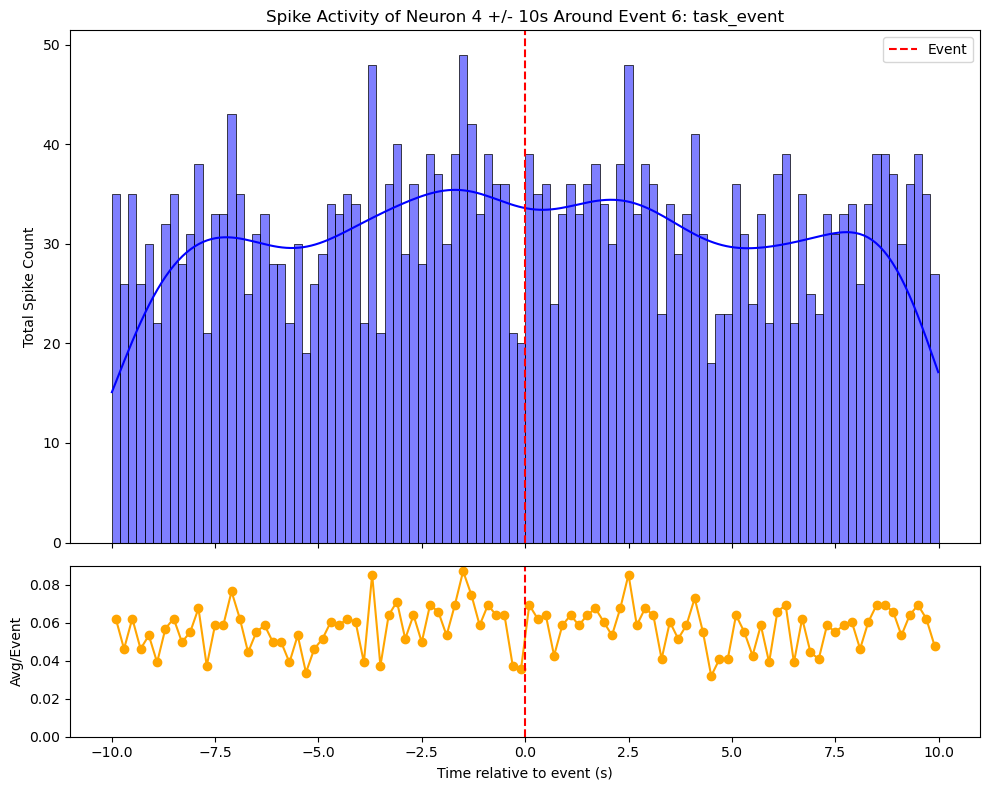

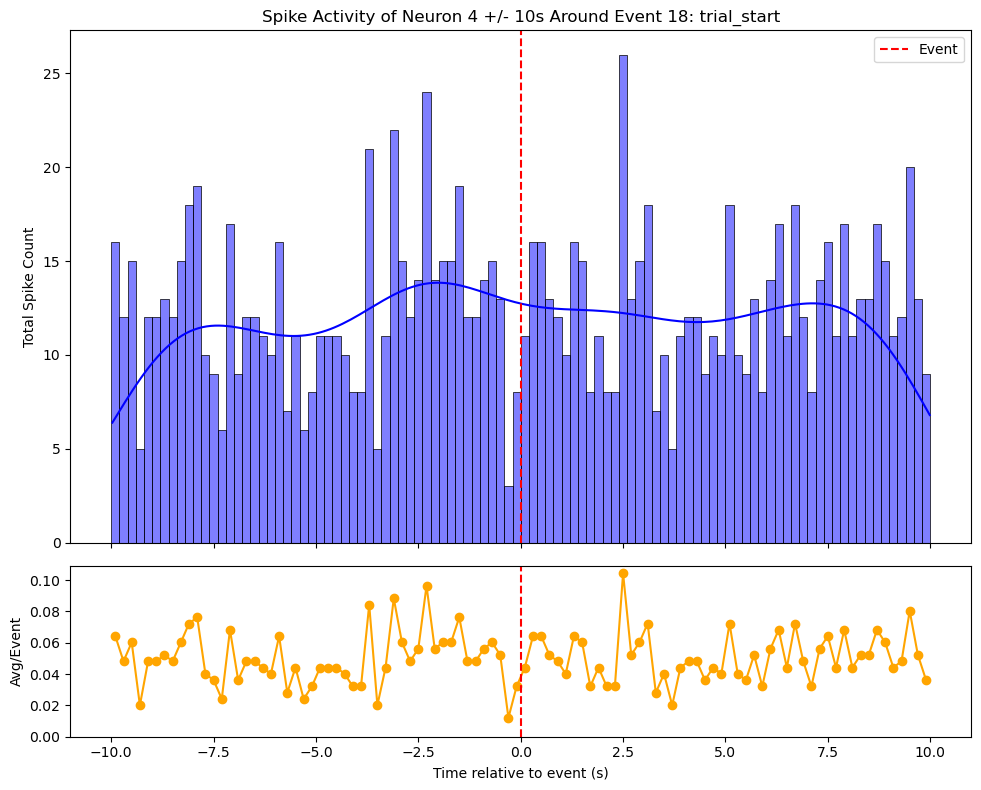

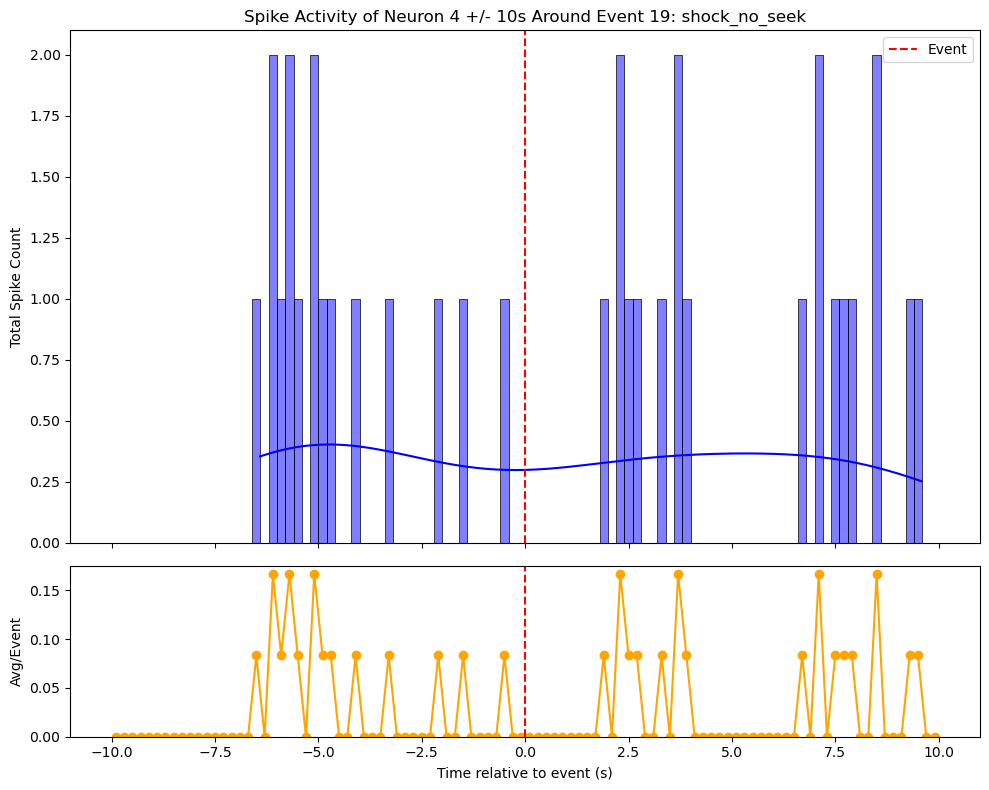

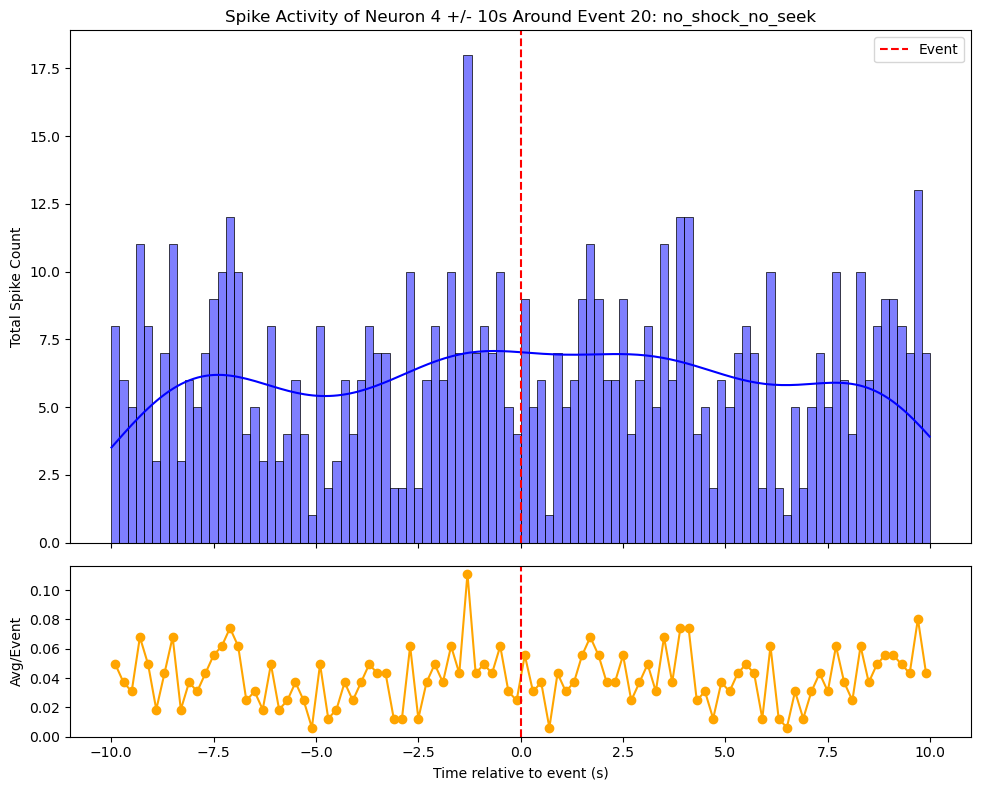

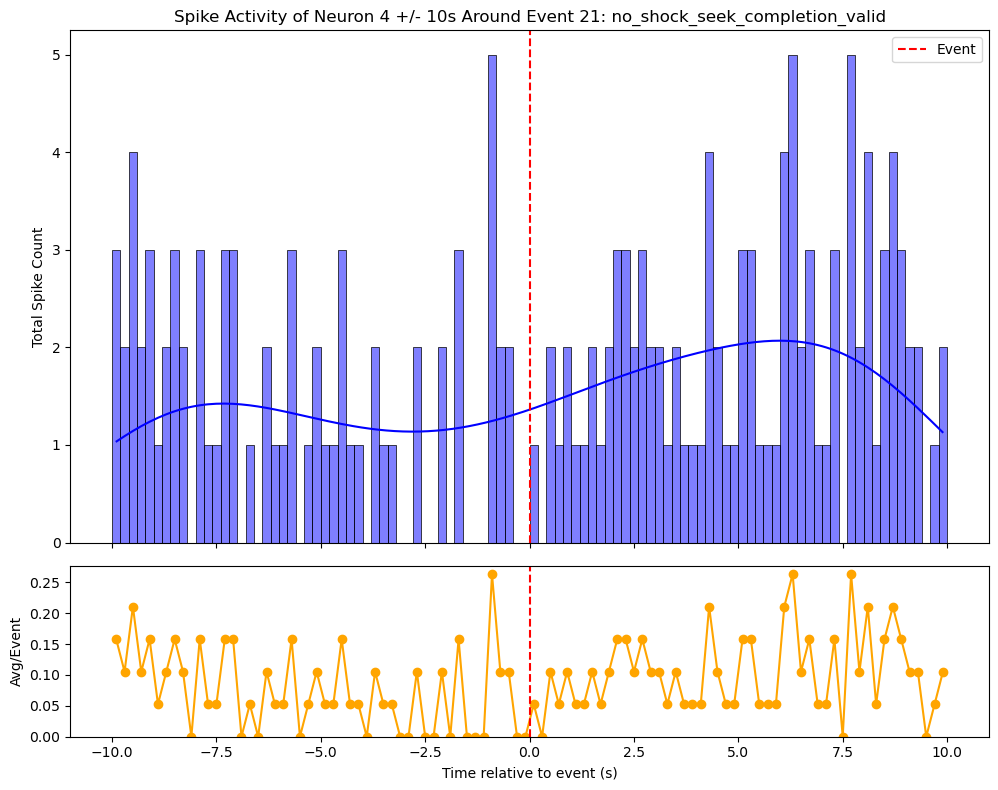

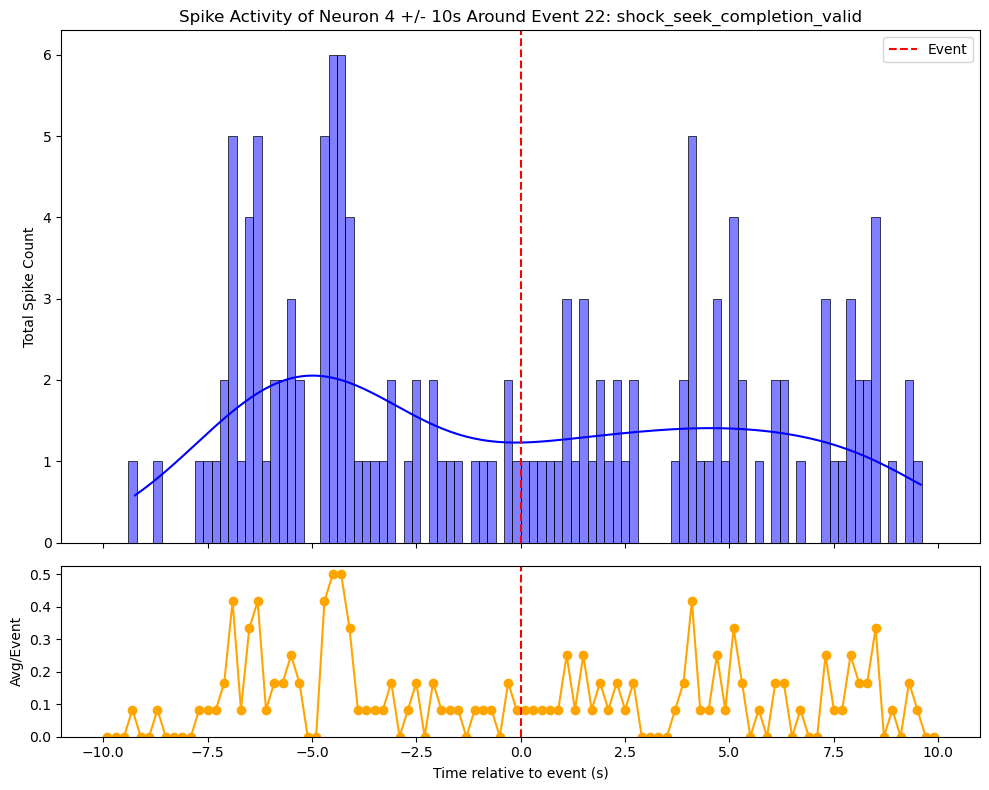

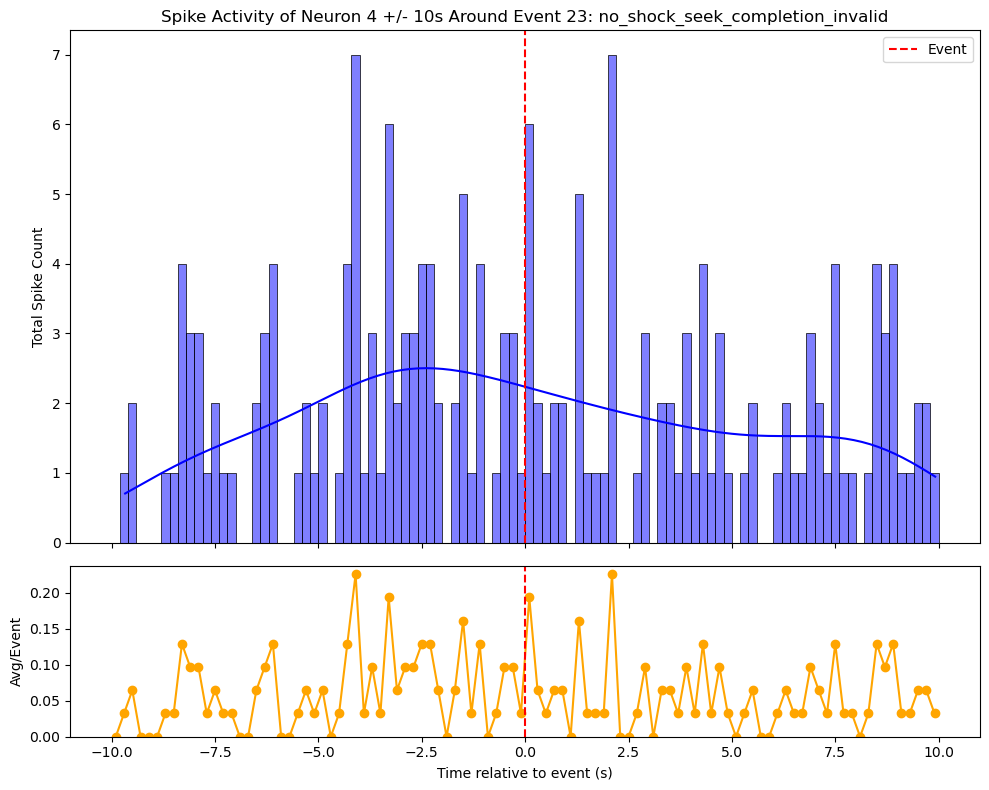

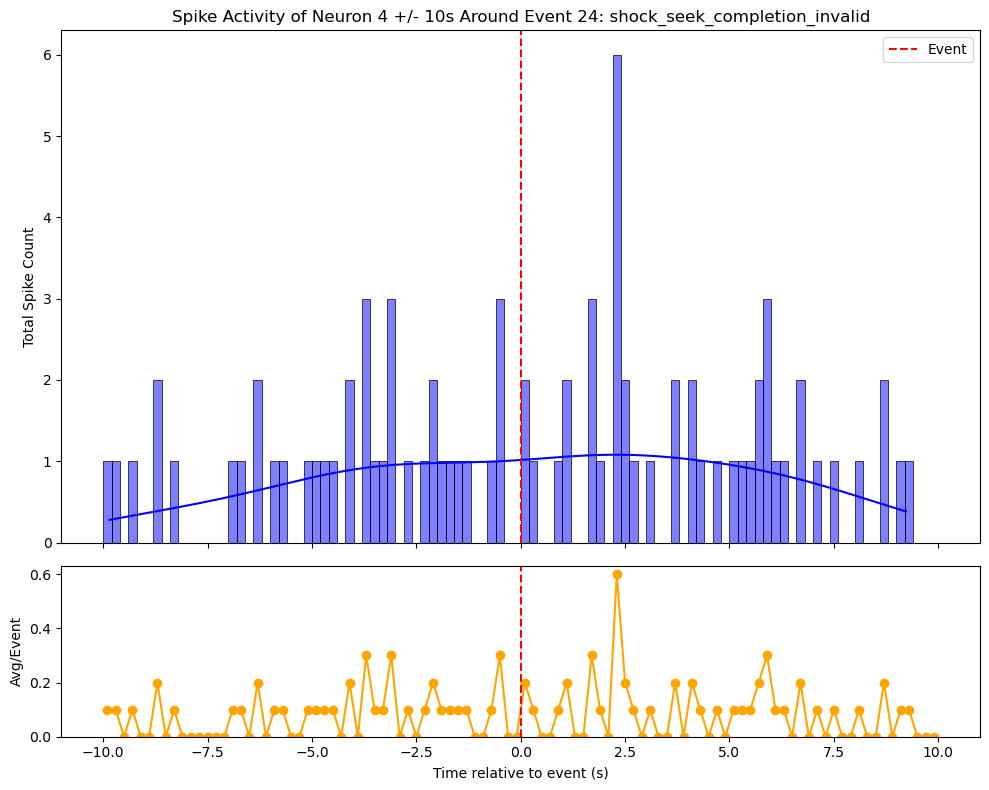

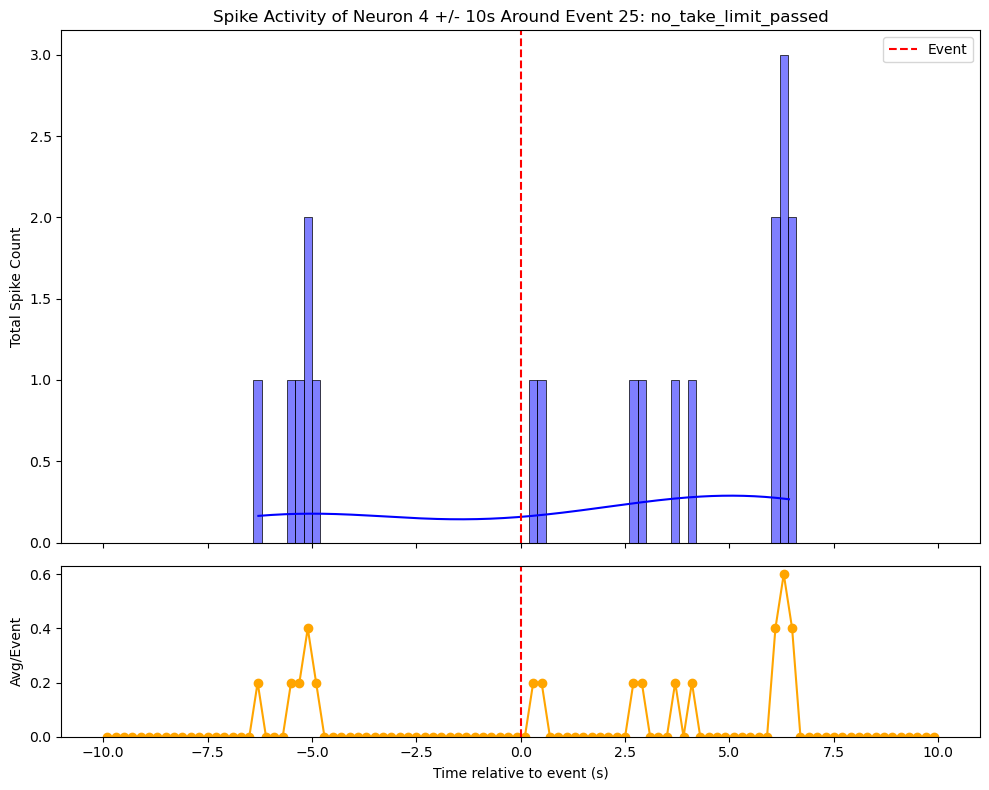

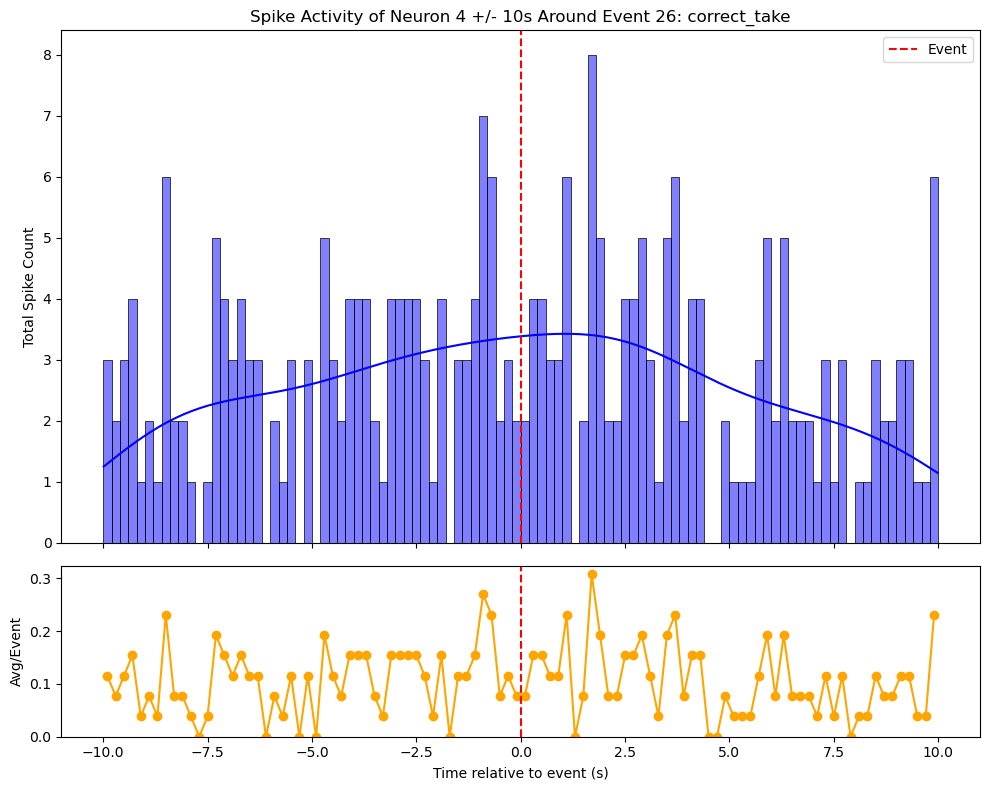

In [19]:

%matplotlib inline
unit = 4

for event in list(code_mapping.keys()):
        
    event_timestamps = np.array(events[event])
    num_events = len(event_timestamps)

    time_window = 10
    spike_times = spike_dict_sec[unit]

    spikes_around_events = []
    for event_time in event_timestamps:
        spikes_in_window = spike_times[(spike_times >= event_time - time_window) & 
                                       (spike_times <= event_time + time_window)]
        spikes_shifted = spikes_in_window - event_time
        spikes_around_events.extend(spikes_shifted)

    # Bin setup
    bin_edges = np.linspace(-time_window, time_window, 101)  # 25 bins
    bin_centers = (bin_edges[:-1] + bin_edges[1:]) / 2

    # Histogram (summed spike count)
    summed_counts, _ = np.histogram(spikes_around_events, bins=bin_edges)

    # Average per event
    avg_counts = summed_counts / num_events

    # Plot both
    fig, axs = plt.subplots(2, 1, figsize=(10,8), sharex=True, gridspec_kw={'height_ratios': [3, 1]})
    
    # Top: Total spike counts
    sns.histplot(spikes_around_events, bins=bin_edges, kde=True, ax=axs[0], color='blue', stat='count', edgecolor='black')
    axs[0].axvline(0, color='red', linestyle='--', label='Event')
    axs[0].set_ylabel('Total Spike Count')
    axs[0].set_title(f'Spike Activity of Neuron {unit} +/- {time_window}s Around Event {event}: {code_mapping[event]}')
    axs[0].legend()
    


    # Bottom: Average spike counts
    axs[1].plot(bin_centers, avg_counts, color='orange', marker='o')
    axs[1].axvline(0, color='red', linestyle='--')
    axs[1].set_xlabel('Time relative to event (s)')
    axs[1].set_ylabel('Avg/Event')
    axs[1].set_ylim(bottom=0)

    plt.tight_layout()
    plt.show()

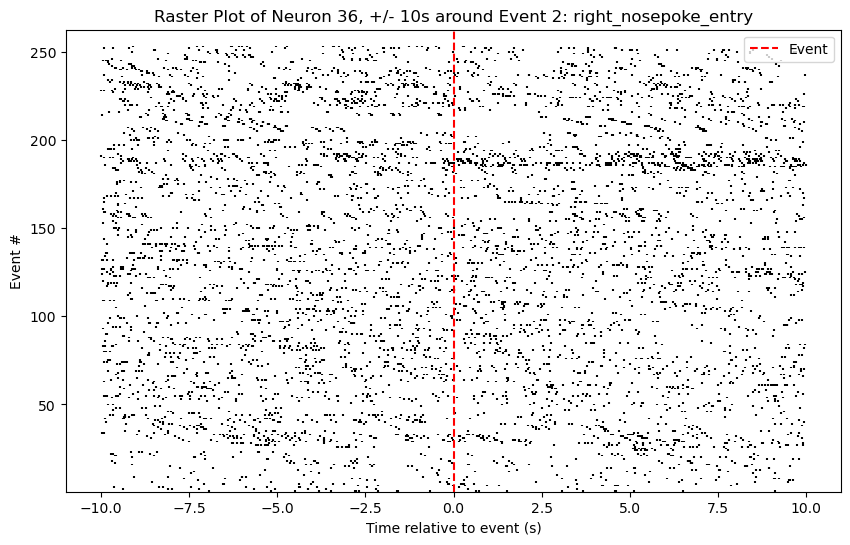

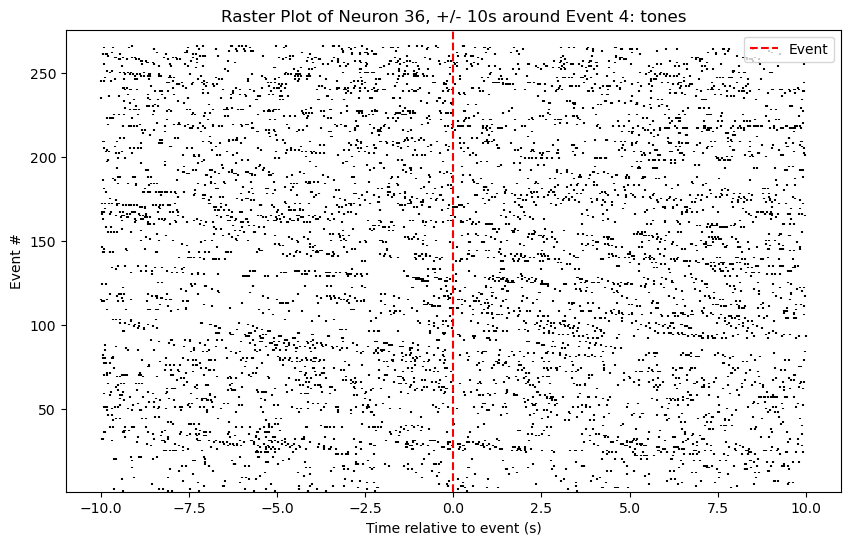

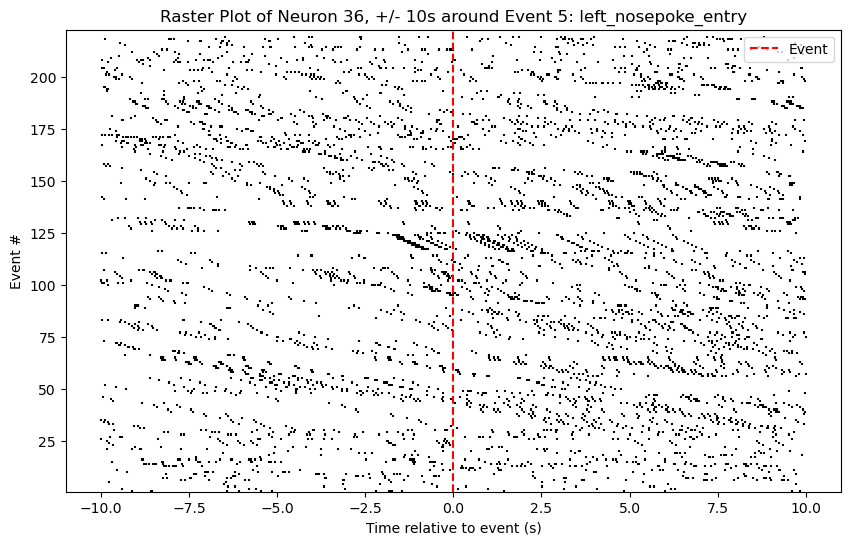

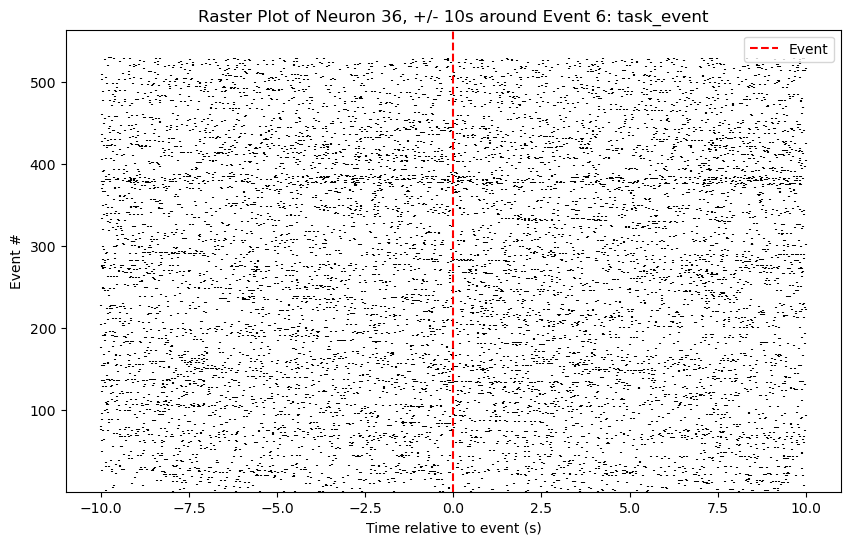

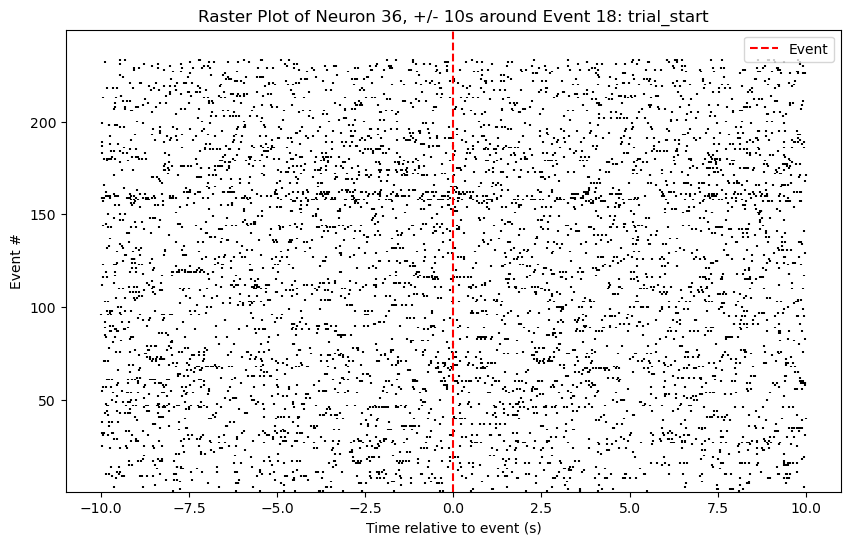

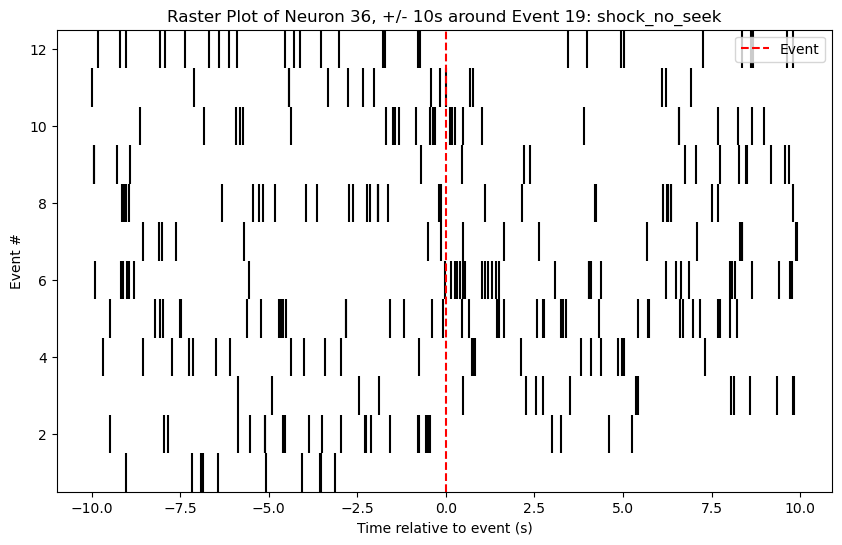

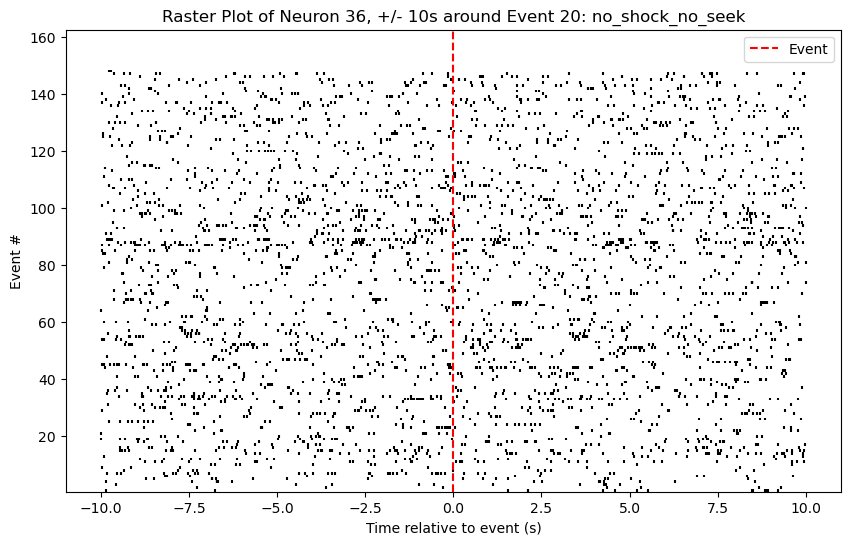

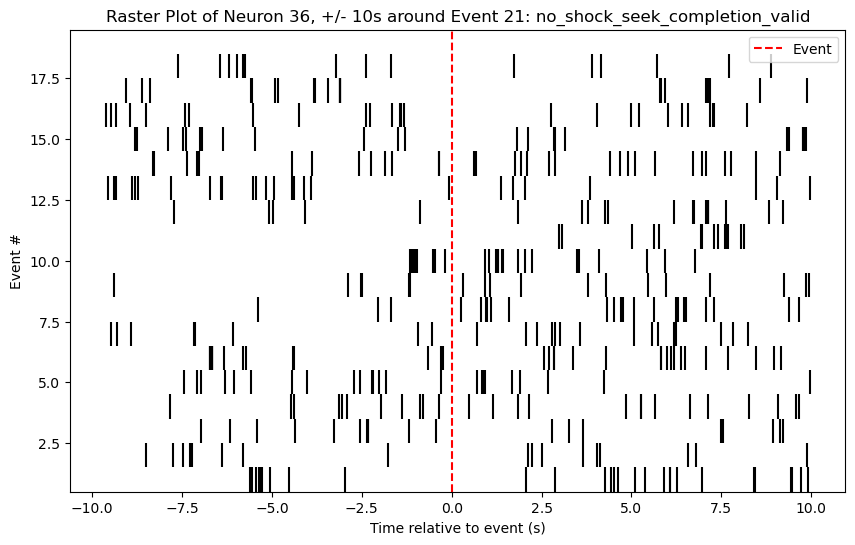

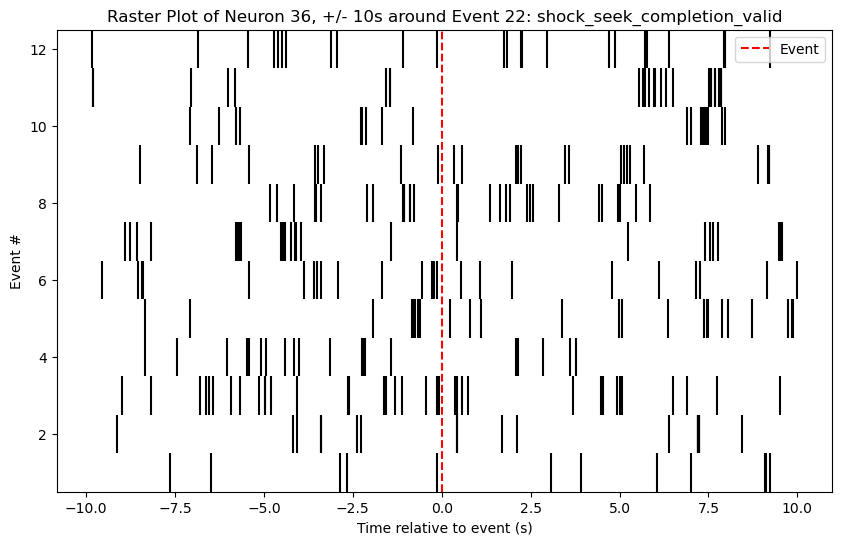

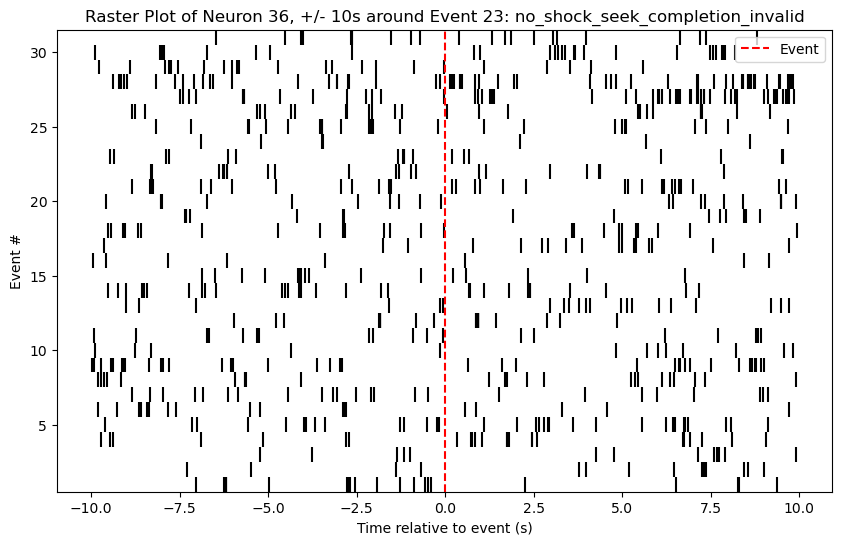

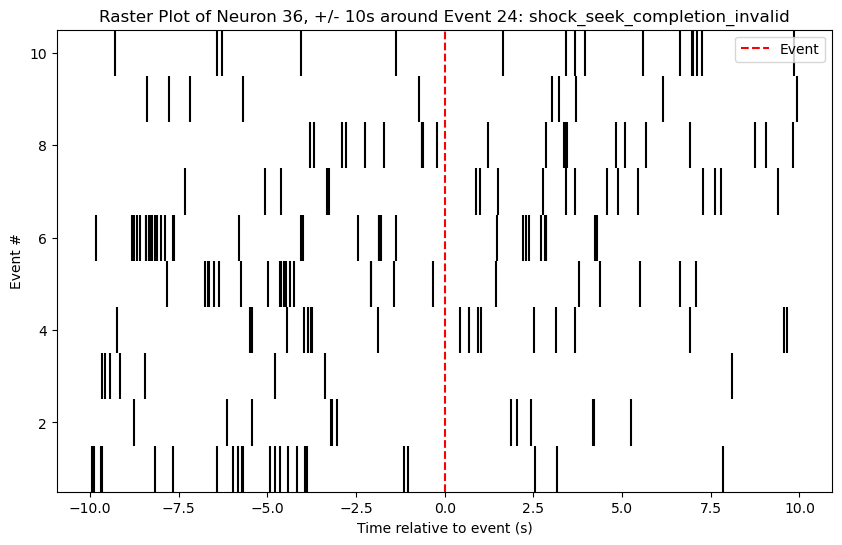

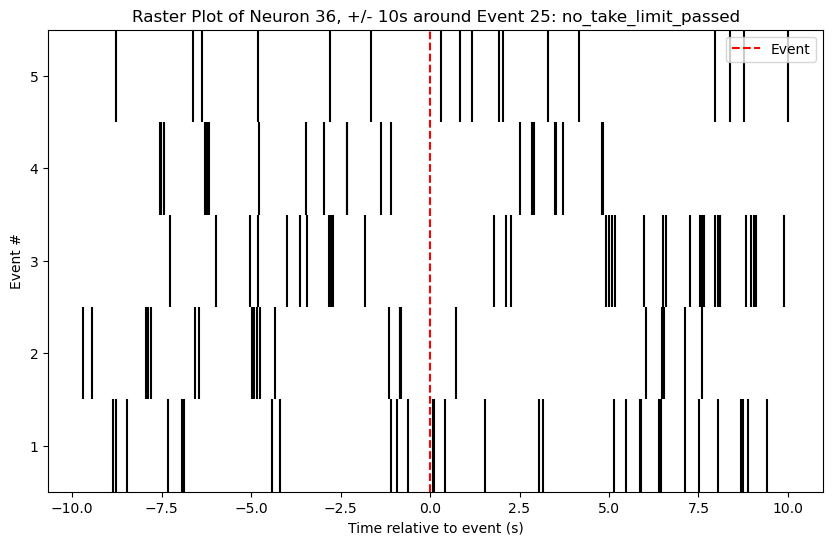

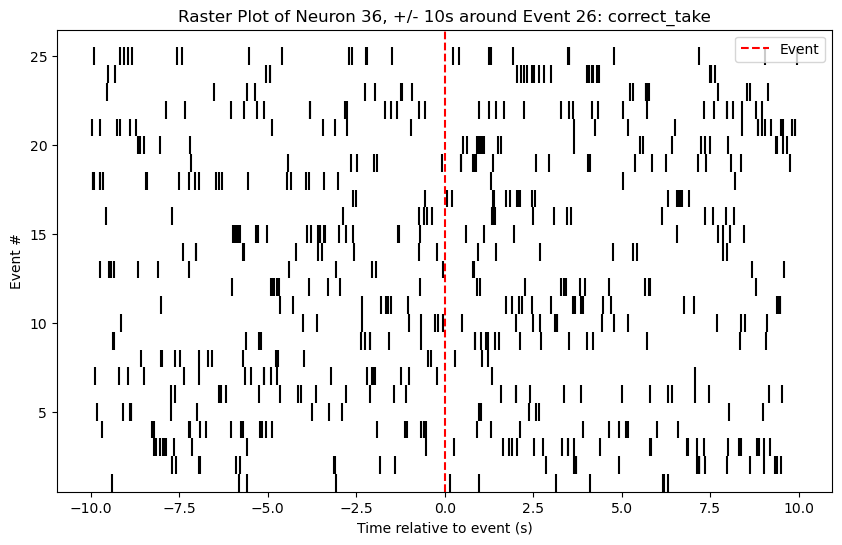

In [20]:
time_window = 10
unit = 36
for event in list(code_mapping.keys()):
    spike_times = spike_dict_sec[unit]  
    event_timestamps = np.array(events[event])

    plt.figure(figsize=(10, 6))

    for trial_idx, event_time in enumerate(event_timestamps):
        spikes_in_window = spike_times[(spike_times >= event_time - time_window) & 
                                        (spike_times <= event_time + time_window)]
        spikes_shifted = spikes_in_window - event_time
        
        for spike_time in spikes_shifted:
            plt.vlines(spike_time, trial_idx + 0.5, trial_idx + 1.5, color='black')

    plt.axvline(0, color='red', linestyle='--', label='Event')
    plt.xlabel('Time relative to event (s)')
    plt.ylabel('Event #')
    plt.title(f'Raster Plot of Neuron {unit}, +/- {time_window}s around Event {event}: {code_mapping[event]}')
    plt.ylim(0.5, len(event_timestamps) + 0.5)
    plt.legend()
    plt.show()
